# Evaluator-optimiser — refining a story outline

[Open Colab](https://colab.research.google.com/) and choose **File → Upload notebook** to open this English copy.

**Audience** — Developers new to agents who are familiar with Python functions and async/await.

**Learning objective** — Build a generator and evaluator that revise an outline until it passes or reaches the round limit.

**Sequence** — Set up the environment, define inputs and agents, run the workflow, check the results, then try an exercise.

[Source code](../src/main.py) · [Example guide](../README.md) · [Environment setup](../../../../../docs/setup.md)

### Pattern architecture

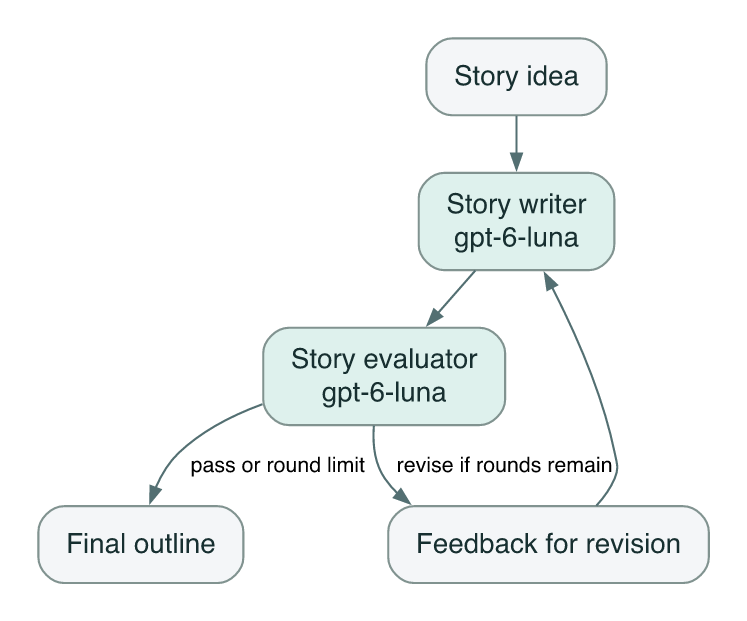

### From diagram to code

| Diagram element | Implementation | Role |
| --- | --- | --- |
| User Query | `topic` | Subject of the story |
| Agent 1 | `generator` | Drafts the outline and incorporates feedback |
| Oracle | `evaluator` and `Feedback` | Evaluates the result and returns structured feedback |
| Failure loop | `feedback.score != "pass"` | Adds feedback to the input history and generates a new draft |
| Success path | `feedback.score == "pass"` | Ends the loop |
| Output | `outline` | Final story outline |

#### Execution flow

1. The `generator` creates the first outline.
2. The `evaluator` assesses it and returns `Feedback`.
3. If the outline needs work, append the feedback to `history` and generate a revision.
4. Stop when the outline passes or the loop reaches `MAX_ROUNDS`.

#### How the example implements the diagram

The diagram assumes the oracle can judge quality more reliably than the generator. This exercise uses the same `MODEL` for both agents to illustrate control flow. For quality control in practice, use a more reliable evaluator model or evaluation criteria appropriate to the task.

## 1. Set up the environment

### Colab

1. In Colab, choose **File → Upload notebook** and select this `.ipynb` file. A CPU runtime is sufficient. You can run it without cloning the repository or mounting Google Drive.
2. The setup cell installs `openai-agents==0.22.1` and `python-dotenv` if needed. If you already imported a different SDK version, restart the runtime and run from the top.
3. For live calls, open **Secrets** (the key icon in the left sidebar), add your existing key as `OPENAI_API_KEY`, and enable access for this notebook. Keep keys out of code cells. Your local `.env.local` file is not copied into Colab.

### Local Jupyter

Install the shared notebook environment with `uv` and select its kernel. Existing environment variables take precedence. If a `.env.local` file exists in the current directory or a parent, the notebook reads additional settings from it. Offline exercises require neither the file nor a key.

### Run settings

The default `RUN_API=False` builds the agents and runs offline exercises without reading Secrets or calling the API. To see live results, set `RUN_API=True` in the next cell and run the following cells in order. Key lookup order is **environment → optional `.env.local` → Colab Secrets**. The notebook never prints or saves key values. Model calls and web searches may incur charges. Jupyter supports top-level `await` in its existing event loop.

The standalone example later in the notebook has its own `run_api=True` argument, independent of `RUN_API`.


In [ ]:
import os
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

# Install only in Colab. Local environments use requirements-notebooks.txt.
try:
    import google.colab
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    try:
        dependencies_ready = (
            version("openai-agents") == "0.22.1"
            and version("python-dotenv").split(".")[0] == "1"
        )
    except PackageNotFoundError:
        dependencies_ready = False
    if not dependencies_ready:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "--quiet",
            "openai-agents==0.22.1", "python-dotenv>=1,<2",
        ])

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


RUN_API = False  # Set True for the walkthrough's API and web search calls.
MODEL = load_environment(run_api=RUN_API)
set_tracing_disabled(True)
print({"environment": "Colab" if IN_COLAB else "local", "model": MODEL, "api_enabled": RUN_API})


## 2. Define the generator and evaluator

Use structured evaluation results to decide what to do next. Reaching the round limit can leave the outline below the quality threshold.

In [ ]:
from typing import Literal

from pydantic import BaseModel


class Feedback(BaseModel):
    score: Literal["pass", "needs_improvement", "fail"]
    feedback: str


generator = Agent(
    name="Story writer",
    model=MODEL,
    instructions=(
        "Write a short story outline (under 120 words). "
        "Incorporate any feedback."
    ),
)

evaluator = Agent(
    name="Story evaluator",
    model=MODEL,
    output_type=Feedback,
    instructions=(
        "Pass only if the outline includes a detective, a space setting, "
        "a concrete mystery, and a resolution. Otherwise provide specific "
        "actionable feedback."
    ),
)

topic = "A detective story in space."
MAX_ROUNDS = 3

assert 1 <= MAX_ROUNDS <= 5

## 3. Run the feedback loop (API calls)

Append feedback to the previous run's input list. Stop on `pass` or when the loop reaches its round limit.

In [ ]:
history = [{"role": "user", "content": topic}]
rounds = []
outline = None
passed = False

if RUN_API:
    for round_number in range(1, MAX_ROUNDS + 1):
        draft = await Runner.run(generator, history, max_turns=2)
        history = draft.to_input_list()
        outline = str(draft.final_output)
        judged = await Runner.run(evaluator, outline, max_turns=2)
        feedback = judged.final_output
        rounds.append({"round": round_number, **feedback.model_dump()})

        print(round_number, feedback.score, feedback.feedback)

        if feedback.score == "pass":
            passed = True
            break

        history.append(
            {
                "role": "user",
                "content": (
                    "Improve the outline using this feedback: "
                    f"{feedback.feedback}"
                ),
            }
        )

    print("Passed" if passed else "Round limit reached without passing")
    print(outline)
else:
    print("API call skipped")

## 4. Check the stopping condition

Check whether the outline passed or the loop exhausted its rounds.

In [ ]:
if RUN_API:
    assert 1 <= len(rounds) <= MAX_ROUNDS
    assert outline and outline.strip()
    assert passed or len(rounds) == MAX_ROUNDS
    assert passed == (rounds[-1]["score"] == "pass")

## 5. Run the workflow as a Python module with `main()`

The preceding cells walk through the workflow step by step. The next cell packages the same workflow as an independent Python module. Once the dependencies are installed, you can start with this cell because it defines its own agents and variables.

A function coordinates two agents: the generator writes the outline and the evaluator reviews it. Like the upstream example, this version uses `main()` as its entry point. It keeps the notebook's explicit quality criteria and maximum round count.

| Component | Responsibility |
| --- | --- |
| `StoryFeedback` | Defines the evaluation result format |
| `build_story_agents()` | Configures the generator and evaluator |
| `refine_story()` | Runs the generation, evaluation, and revision loop and handles termination |
| `main()` | Loads settings, passes input to the workflow, and prints the result |

Use `main(run_api=...)` to choose whether to call the API. The default is `False`. Defining the functions makes no calls. Enabling live execution incurs charges.


In [ ]:
import asyncio
import os
from typing import Literal

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv
from pydantic import BaseModel


class StoryFeedback(BaseModel):
    score: Literal["pass", "needs_improvement", "fail"]
    feedback: str


def build_story_agents(model: str) -> tuple[Agent, Agent]:
    """Create the generator and evaluator for one workflow run."""
    generator = Agent(
        name="Story writer",
        model=model,
        instructions=(
            "Write a short story outline (under 120 words). "
            "Incorporate any feedback."
        ),
    )

    evaluator = Agent(
        name="Story evaluator",
        model=model,
        output_type=StoryFeedback,
        instructions=(
            "Pass only if the outline includes a detective, a space setting, "
            "a concrete mystery, and a resolution. Otherwise provide specific "
            "actionable feedback."
        ),
    )

    return generator, evaluator


async def refine_story(
    topic: str,
    *,
    model: str,
    max_rounds: int = 3,
) -> dict:
    """Refine an outline and return the result and evaluation history."""
    if not 1 <= max_rounds <= 5:
        raise ValueError("max_rounds must be between 1 and 5.")

    generator, evaluator = build_story_agents(model)
    history = [{"role": "user", "content": topic}]
    rounds = []
    outline = ""
    passed = False

    for round_number in range(1, max_rounds + 1):
        draft = await Runner.run(generator, history, max_turns=2)
        history = draft.to_input_list()
        outline = str(draft.final_output)

        judged = await Runner.run(evaluator, outline, max_turns=2)
        feedback = judged.final_output
        rounds.append({"round": round_number, **feedback.model_dump()})

        if feedback.score == "pass":
            passed = True
            break

        history.append(
            {
                "role": "user",
                "content": (
                    "Improve the outline using this feedback: "
                    f"{feedback.feedback}"
                ),
            }
        )

    return {"outline": outline, "passed": passed, "rounds": rounds}


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


async def main(
    topic: str = "A detective story in space.",
    *,
    run_api: bool = False,
    max_rounds: int = 3,
) -> dict | None:
    """Load configuration, run the workflow, and present its results."""
    model = load_environment(run_api=run_api)
    set_tracing_disabled(True)

    if not run_api:
        print("API call skipped. Pass run_api=True to enable it.")
        return None

    result = await refine_story(topic, model=model, max_rounds=max_rounds)

    for evaluation in result["rounds"]:
        print(
            evaluation["round"],
            evaluation["score"],
            evaluation["feedback"],
        )

    print("Passed" if result["passed"] else "Round limit reached without passing")
    print(result["outline"])

    return result


### Calling the workflow in a notebook

Jupyter already runs an event loop, so use `await main(...)`. The next cell skips API calls by default. Set `run_api=True` for a new live run, independent of any earlier guided run.


In [ ]:
standalone_result = await main(
    topic="A detective story in space.",
    run_api=False,  # Set to True to run this standalone workflow.
    max_rounds=3,
)


### Running `story_agent.py`

1. Copy the **entire function definition cell** into `story_agent.py`. Leave the notebook-only `await main(...)` invocation in the notebook.

2. Add the following entry point at the bottom of the file. API calls run only when you pass `--run-api`.

   ```python
   if __name__ == "__main__":
       import argparse

       parser = argparse.ArgumentParser(description="Refine a story outline.")
       parser.add_argument("--run-api", action="store_true")
       args = parser.parse_args()

       asyncio.run(main(run_api=args.run_api))
   ```

3. Activate the virtual environment containing the exercise dependencies and run the commands below. For live calls, set `OPENAI_API_KEY` in the environment or the optional `.env.local` file.

   ```bash
   python story_agent.py            # Check configuration; skip API calls
   python story_agent.py --run-api  # Run the workflow; API costs apply
   ```

In another Python module, use `from story_agent import refine_story` and call `await refine_story(topic, model=...)`. The calling application supplies environment variables and tracing configuration. The `if __name__ == "__main__":` guard keeps importing the module free of execution side effects.

This standalone example is separate from `src/main.py`. When distributing it, retain the notebook attribution and the repository's `THIRD_PARTY_NOTICES.md`.


## Try it yourself

Add a “final twist” to the evaluation criteria and compare the scores and feedback. To try a stronger evaluator, give it a separate model variable.

## Changes from upstream and limitations

The notebook caps the upstream loop at three rounds and replaces the instruction to fail the first attempt with explicit quality criteria. Both agents use the same model, so the evaluator may share the generator's blind spots.

## Sources

- [Local source](../src/main.py)
- [Official OpenAI example](https://github.com/openai/openai-agents-python/blob/25af629b3c877ba3d0e95189141bb636b21167a5/examples/agent_patterns/llm_as_a_judge.py)
- [Agents SDK guide](https://developers.openai.com/api/docs/guides/agents/sdk)
- [Agents guide](https://developers.openai.com/api/docs/guides/agents)

This notebook adapts the official example for hands-on learning. Model outputs vary between runs.